# 02 - Supervised models

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

from netad.data import load_unsw_frame, overlap_with_train, train_val_split, FEATURES
from netad.preprocessing import build_preprocessor
from netad.evaluation import (
    evaluate_binary, choose_threshold, evaluate_multiclass, evaluate_test,
    save_result, plot_roc_pr, plot_confusion,
)

In [3]:
train_df = load_unsw_frame("train")
test_df = load_unsw_frame("test")

X_test = test_df[FEATURES]
y_test = test_df["label"]
y_test_multi = test_df["attack_cat"]
unseen = ~overlap_with_train(train_df, test_df)

X_tr, X_val, y_tr, y_val = train_val_split(train_df, "label")
Xm_tr, Xm_val, ym_tr, ym_val = train_val_split(train_df, "attack_cat")

len(X_tr), len(X_val), len(Xm_tr), len(Xm_val), len(X_test), int(unseen.sum())

(80752, 20189, 80341, 20086, 82332, 73791)

Binary: the threshold is picked on validation with an FPR budget of 1% and then used as is on test.
Every test result is reported on the full test set and on the unseen rows.

In [4]:
MAX_FPR = 0.01

## Dummy baseline

Predicts the class priors seen in train, the same score for every flow. Used to check the whole flow end to end,
and as the floor any real model has to beat.

In [5]:
dummy = make_pipeline(build_preprocessor(), DummyClassifier(strategy="prior"))
dummy.fit(X_tr, y_tr)

scores_val = dummy.predict_proba(X_val)[:, 1]
scores_test = dummy.predict_proba(X_test)[:, 1]
threshold = choose_threshold(y_val, scores_val, "fpr", max_fpr=MAX_FPR)

metrics = {
    "val": evaluate_binary(y_val, scores_val, threshold),
    **evaluate_test(evaluate_binary, y_test, scores_test, unseen, threshold=threshold),
}
save_result("Dummy (prior)", "binary", metrics, {"threshold_mode": "fpr", "max_fpr": MAX_FPR})

{k: {m: v[m] for m in ["recall", "fpr", "roc_auc", "pr_auc"]} for k, v in metrics.items()}

{'val': {'recall': 0.0,
  'fpr': 0.0,
  'roc_auc': 0.5,
  'pr_auc': 0.4877408489771658},
 'test': {'recall': 0.0,
  'fpr': 0.0,
  'roc_auc': 0.5,
  'pr_auc': 0.5506000097167566},
 'test_unseen': {'recall': 0.0,
  'fpr': 0.0,
  'roc_auc': 0.5,
  'pr_auc': 0.5185320703066769}}

Same scores with the max-F1 threshold: flags every flow.

In [6]:
t_f1 = choose_threshold(y_val, scores_val, "f1")
m = evaluate_binary(y_test, scores_test, t_f1)
m["recall"], m["fpr"], m["precision"]

(1.0, 1.0, 0.5506000097167566)

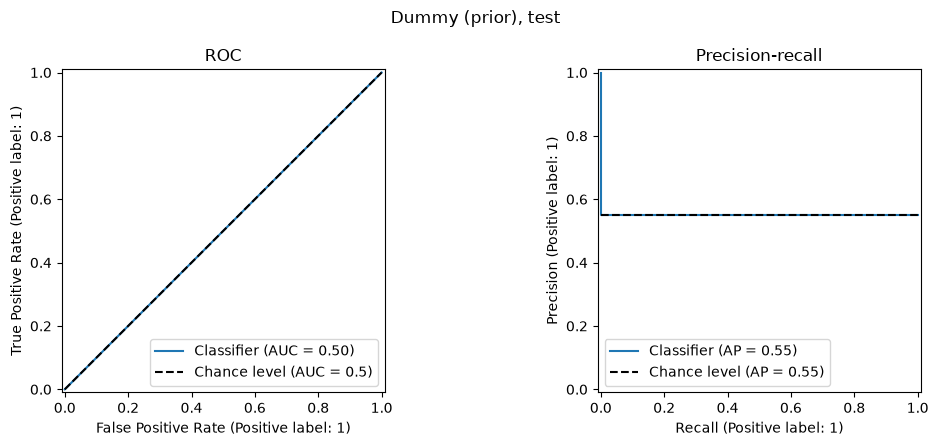

In [7]:
fig = plot_roc_pr(y_test, scores_test, "Dummy (prior), test")
plt.show()

In [8]:
dummy_multi = make_pipeline(build_preprocessor(), DummyClassifier(strategy="most_frequent"))
dummy_multi.fit(Xm_tr, ym_tr)

labels = sorted(ym_tr.unique())
metrics = {
    "val": evaluate_multiclass(ym_val, dummy_multi.predict(Xm_val), labels),
    **evaluate_test(evaluate_multiclass, y_test_multi, dummy_multi.predict(X_test), unseen, labels=labels),
}
save_result("Dummy (most frequent)", "multiclass", metrics)

{k: {m: v[m] for m in ["accuracy", "macro_f1"]} for k, v in metrics.items()}

{'val': {'accuracy': 0.5148859902419596, 'macro_f1': 0.0679768634152754},
 'test': {'accuracy': 0.44939999028324346, 'macro_f1': 0.06201186605436933},
 'test_unseen': {'accuracy': 0.481467929693323,
  'macro_f1': 0.0649987650820077}}

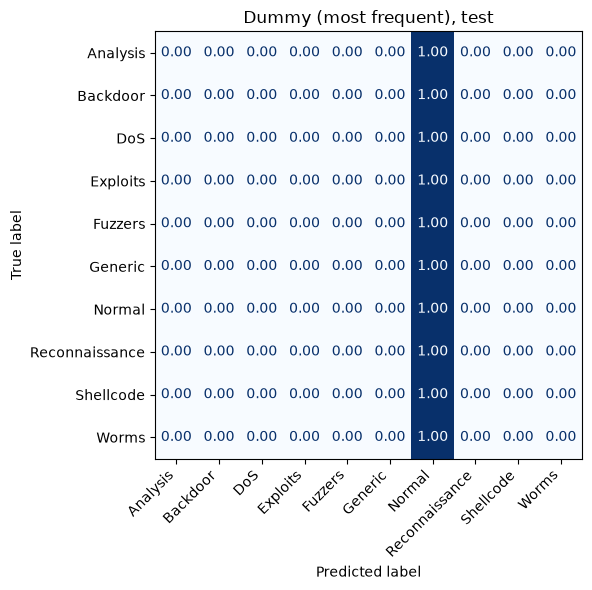

In [9]:
fig = plot_confusion(metrics["test"]["confusion_matrix"], labels, "Dummy (most frequent), test")
plt.show()